# 🏷️ 02. Container Behavioral Clustering & Profiling
### PreZero / Fillinq Challenge: Behavioral Tiering

This notebook separates emptying drops from true accumulation velocity to compute accurate container profiles, and uses **K-Means clustering** to partition locations into 4 operational behavioral tiers.
Outputs are saved to `data/container_clusters.csv`.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.clustering import extract_container_profiles, cluster_containers

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['figure.dpi'] = 110

print("Clustering module loaded.")


Clustering module loaded.


---
## 📥 1. Load Data
Load from `data/cleaned_fill_levels.csv` (or directly from data loader if running standalone).


In [2]:
clean_path = os.path.join("data", "cleaned_fill_levels.csv")
if os.path.exists(clean_path):
    df = pd.read_csv(clean_path)
    df['date'] = pd.to_datetime(df['date'])
else:
    from src.data_loader import load_and_clean_data
    df = load_and_clean_data()

print(f"Loaded {len(df):,} records for clustering.")


Loaded 11,701 records for clustering.


---
## ⚙️ 2. Feature Engineering & Velocity Calculation
We calculate:
* `avg_fill_perc`: Historical mean fill level
* `std_fill_perc`: Fill level volatility
* `overfull_rate`: Percentage of observations $\ge 100\%$
* `daily_fill_velocity`: True median accumulation speed (\%/day) during non-emptying positive periods ($\Delta F \ge 0, \Delta t > 0$).


In [3]:
# Extract profiles for White glass (the primary operational bottleneck)
profiles_white = extract_container_profiles(df, material_filter="white")
print(f"Profiles computed for {len(profiles_white)} unique locations.")
display(profiles_white.head(5))


Profiles computed for 448 unique locations.


,Location_id,readings_count,avg_fill_perc,std_fill_perc,max_fill_perc,overfull_rate,daily_fill_velocity,last_reading_date,current_fill_perc,is_overfull
0,0004c095-29ec-4894-81a8-05f3a7a55650,12,80.000000,33.844564,110.0,16.666667,0.147059,2026-09-10,20.0,False
1,0058ed93-88f5-4c25-8746-2e5ee87e5559,16,76.875000,23.584953,110.0,12.500000,1.428571,2026-09-17,80.0,False
2,009c98f3-c93a-4d55-abfe-79f7acf2a0ff,7,84.285714,19.023795,110.0,14.285714,0.241871,2026-08-25,80.0,False
3,00e9e2cf-b6f7-4872-908b-fcf4c35f388a,17,94.705882,12.805100,110.0,17.647059,0.333333,2026-09-10,100.0,False
4,01371af2-75b4-4b9a-9e74-be20129483d5,5,58.000000,39.623226,110.0,20.000000,1.724138,2026-09-28,20.0,False


---
## 🎯 3. K-Means Behavioral Clustering
Partition into 4 distinct operational tiers:
1. **Tier 1: Critical / Chronic High-Volume:** High fill, high overflow rate, requires frequent dispatch.
2. **Tier 2: Steady High-Demand:** Rapid accumulation, predictable cycles.
3. **Tier 3: Moderate Regular:** Standard suburban/residential accumulation.
4. **Tier 4: Low-Demand / Sporadic:** Slow accumulation, rarely overflows.


In [4]:
clustered_df, kmeans_model = cluster_containers(profiles_white, n_clusters=4, random_state=42)

tier_summary = clustered_df.groupby('tier').agg(
    Container_Count=('Location_id', 'count'),
    Mean_Fill_Level=('avg_fill_perc', 'mean'),
    Avg_Overfull_Rate=('overfull_rate', 'mean'),
    Daily_Fill_Velocity=('daily_fill_velocity', 'mean')
).round(2)

print("=" * 75)
print("             OPERATIONAL CLUSTER PROFILES (WHITE GLASS)")
print("=" * 75)
display(tier_summary)


             OPERATIONAL CLUSTER PROFILES (WHITE GLASS)


,Container_Count,Mean_Fill_Level,Avg_Overfull_Rate,Daily_Fill_Velocity
tier,,,,
Tier 1: Critical / Chronic High-Volume,115,88.11,28.95,0.33
Tier 2: Steady High-Demand,154,85.33,8.88,0.38
Tier 3: Moderate Regular,107,75.17,14.19,1.04
Tier 4: Low-Demand / Sporadic,72,61.20,3.15,0.37


---
## 📊 4. Cluster Visualization


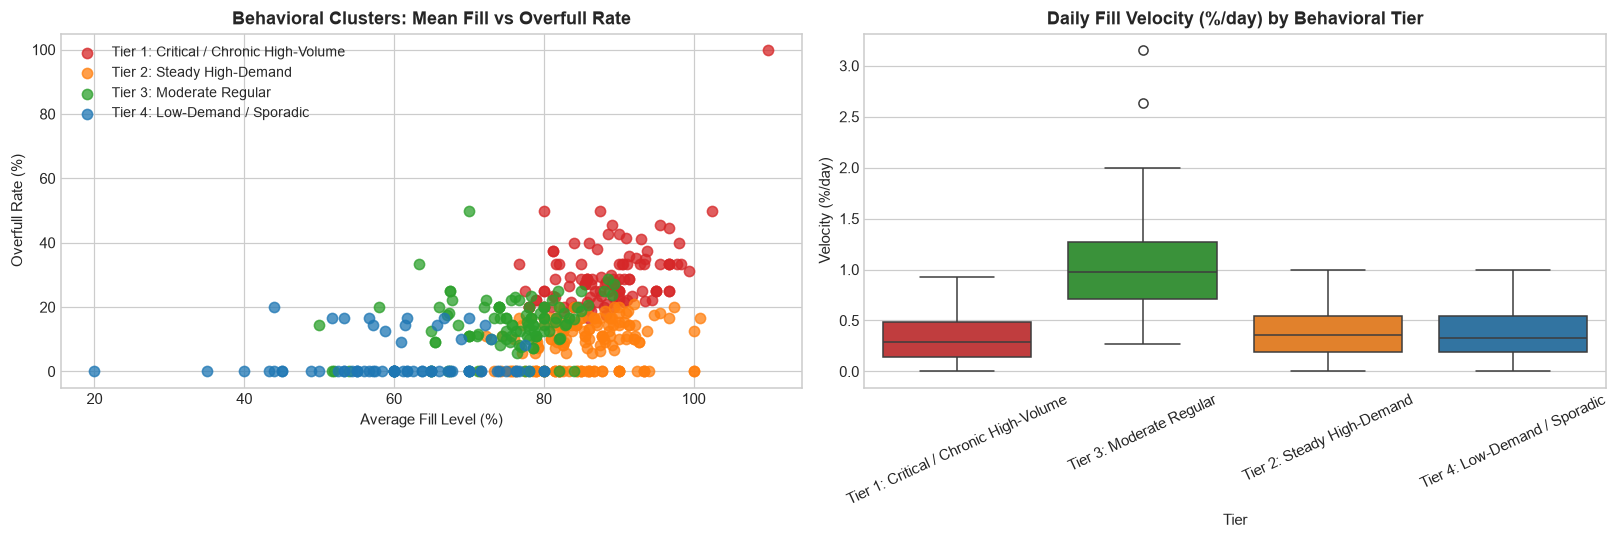

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

tier_palette = {
    'Tier 1: Critical / Chronic High-Volume': '#d62728',
    'Tier 2: Steady High-Demand': '#ff7f0e',
    'Tier 3: Moderate Regular': '#2ca02c',
    'Tier 4: Low-Demand / Sporadic': '#1f77b4'
}

for tier_name, color in tier_palette.items():
    sub = clustered_df[clustered_df['tier'] == tier_name]
    axes[0].scatter(sub['avg_fill_perc'], sub['overfull_rate'], label=tier_name, color=color, alpha=0.75, s=45)

axes[0].set_title("Behavioral Clusters: Mean Fill vs Overfull Rate", fontweight='bold')
axes[0].set_xlabel("Average Fill Level (%)")
axes[0].set_ylabel("Overfull Rate (%)")
axes[0].legend(fontsize=9)

sns.boxplot(data=clustered_df, x='tier', y='daily_fill_velocity', palette=tier_palette, ax=axes[1])
axes[1].set_title("Daily Fill Velocity (%/day) by Behavioral Tier", fontweight='bold')
axes[1].set_xlabel("Tier")
axes[1].set_ylabel("Velocity (%/day)")
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()


---
## 💾 5. Save Clustered Profiles


In [6]:
output_path = os.path.join("data", "container_clusters.csv")
clustered_df.to_csv(output_path, index=False)
print(f"Container behavioral clusters saved to: {output_path}")


Container behavioral clusters saved to: data\container_clusters.csv
